[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\stati\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\stati\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\stati\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Error loading omw-eng: Package 'omw-eng' not found in
[nltk_data]     index


MEDICAL REVIEW EMOTION ANALYSIS
Dataset loaded successfully from 'Final Medicine Reviews 4500 '
File shape: (4500, 3)
Columns: ['Medicine', 'Review', 'Emotion']
DATA PREPARATION SUMMARY
Text column detected: Review
Label column detected: Emotion
Original dataset shape: (4500, 3)
Original columns: ['Medicine', 'Review', 'Emotion']

Sample of original data (first 5 rows):
                                              Review   Emotion
0  I DID GREAT ONE IT, HOWEVER IF I KNEW HOW HARD...  surprise
1  I WAS PUT ON 150 MG OF EFFEXOR WHEN CELEXA STO...  surprise
2  Lost weight initially.  Now am up to 300mg - s...  surprise
3  i have been taking this drug for over 2 years ...  surprise
4  AN AWESOME TREATMENT FOR DEPRESSION. BUT WHEN ...  surprise

Missing values in text column: 1
Missing values in label column: 0

Samples after removing invalid data: 4499
Samples removed: 1
Samples after removing empty cleaned text: 4499
Additional samples removed: 0

LABEL DISTRIBUTION AFTER CLEANING
anger 

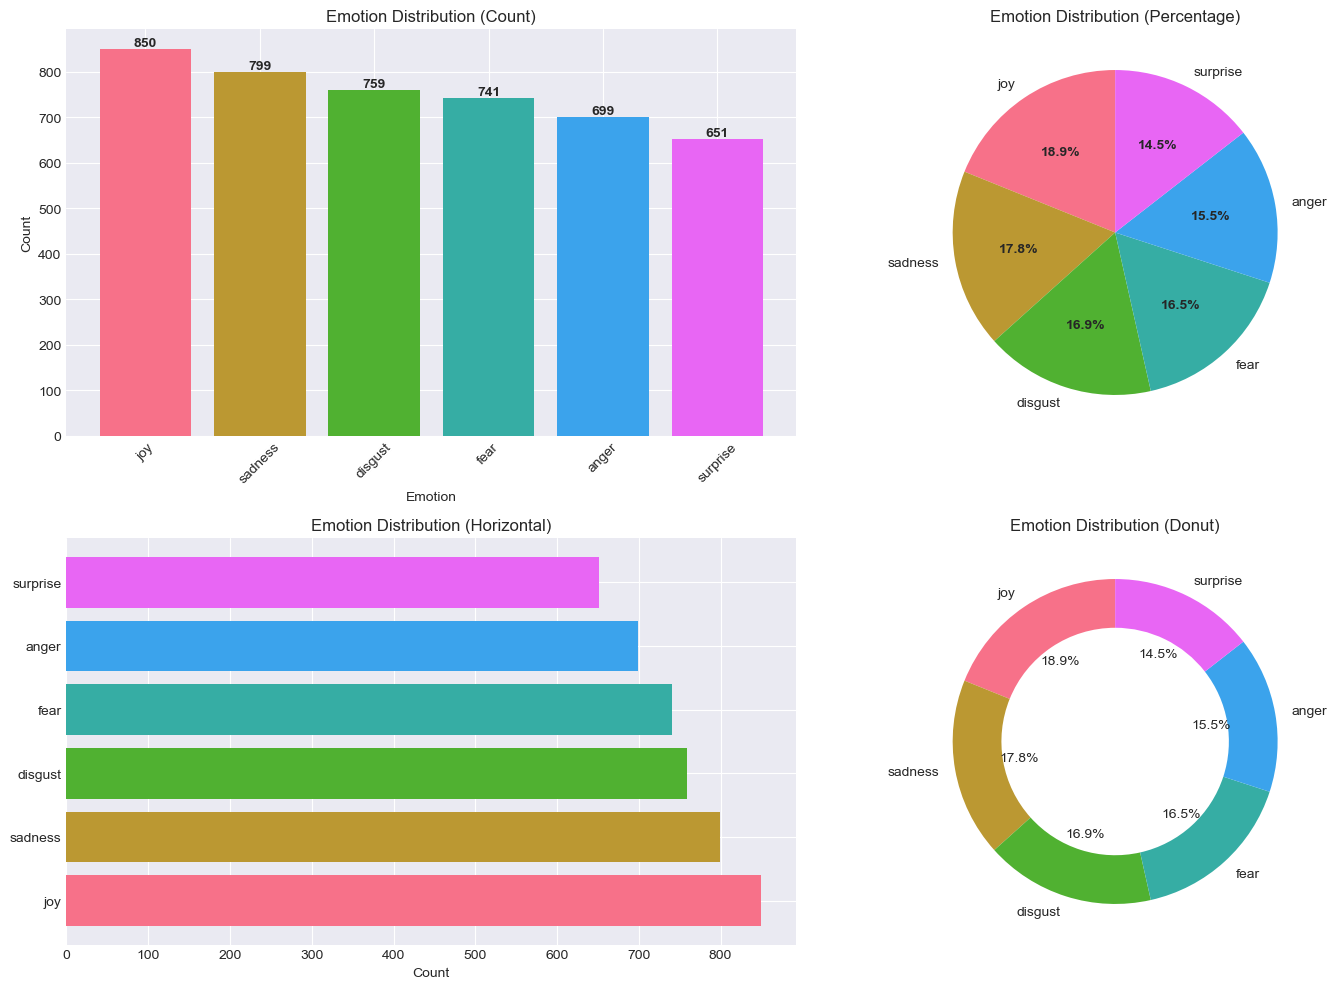

EMOTION DISTRIBUTION STATISTICS
Total samples: 4499
Number of unique emotions: 6

Count by emotion:
  joy            :  850 ( 18.9%)
  sadness        :  799 ( 17.8%)
  disgust        :  759 ( 16.9%)
  fear           :  741 ( 16.5%)
  anger          :  699 ( 15.5%)
  surprise       :  651 ( 14.5%)

Most common emotion: joy (850 samples)
Least common emotion: surprise (651 samples)
Imbalance ratio: 1.31:1

3. TEXT LENGTH ANALYSIS:


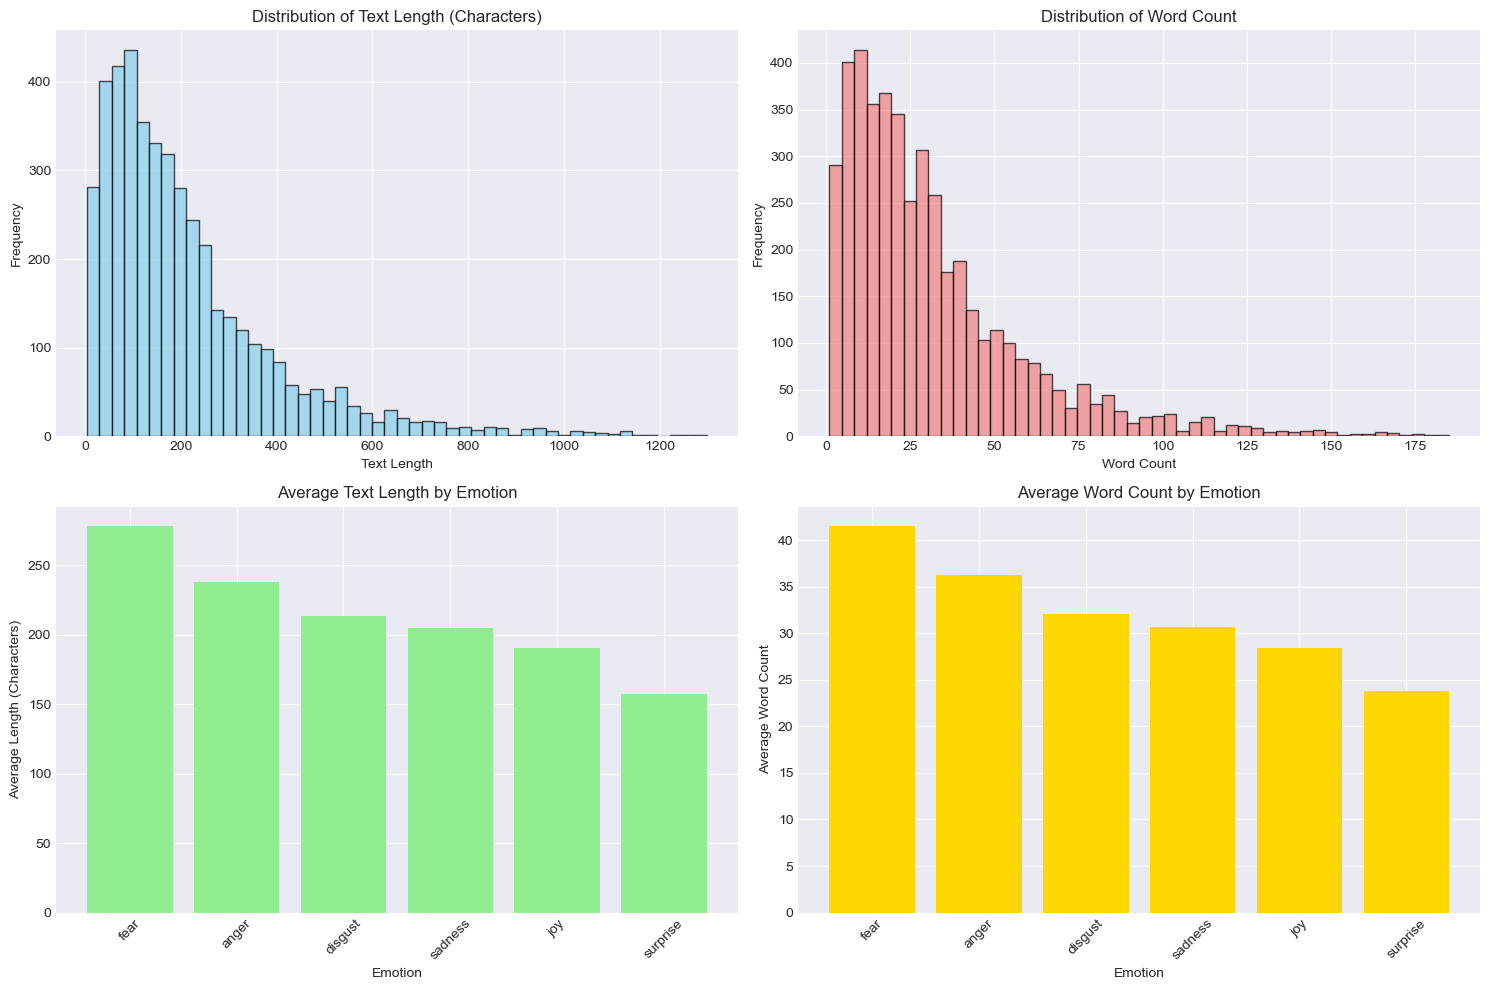


4. TEXT CLEANING ANALYSIS:


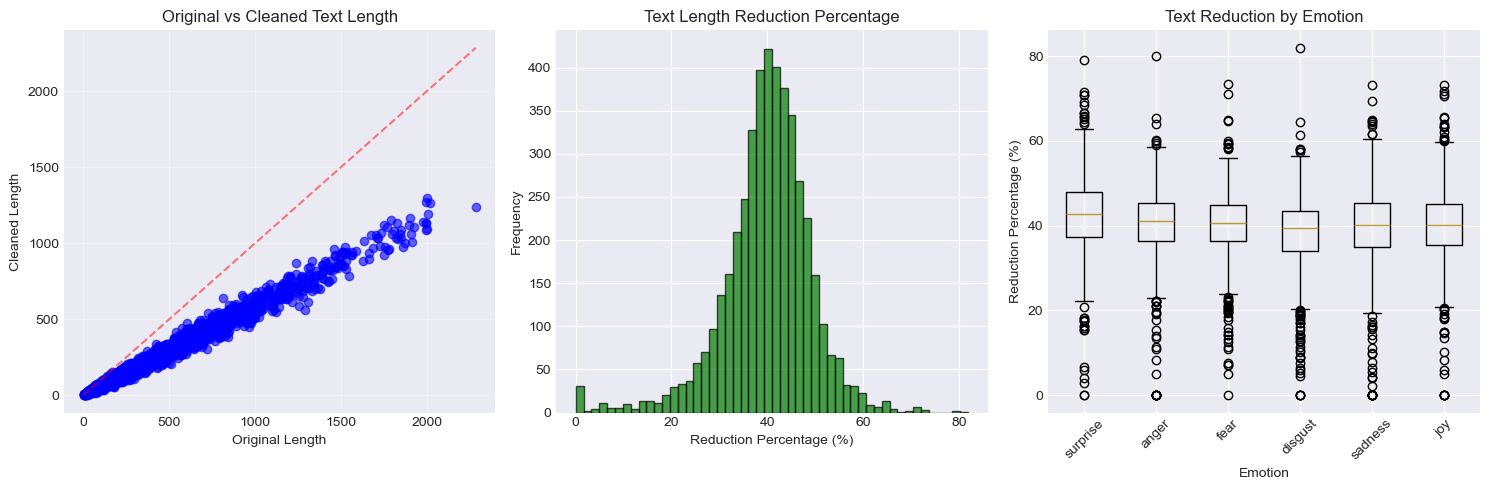


TEXT CLEANING STATISTICS
Average original text length: 363.3 characters
Average cleaned text length: 213.9 characters
Average reduction: 39.9%
Maximum reduction: 81.9%
Minimum reduction: 0.0%

5. COMMON WORDS ANALYSIS:


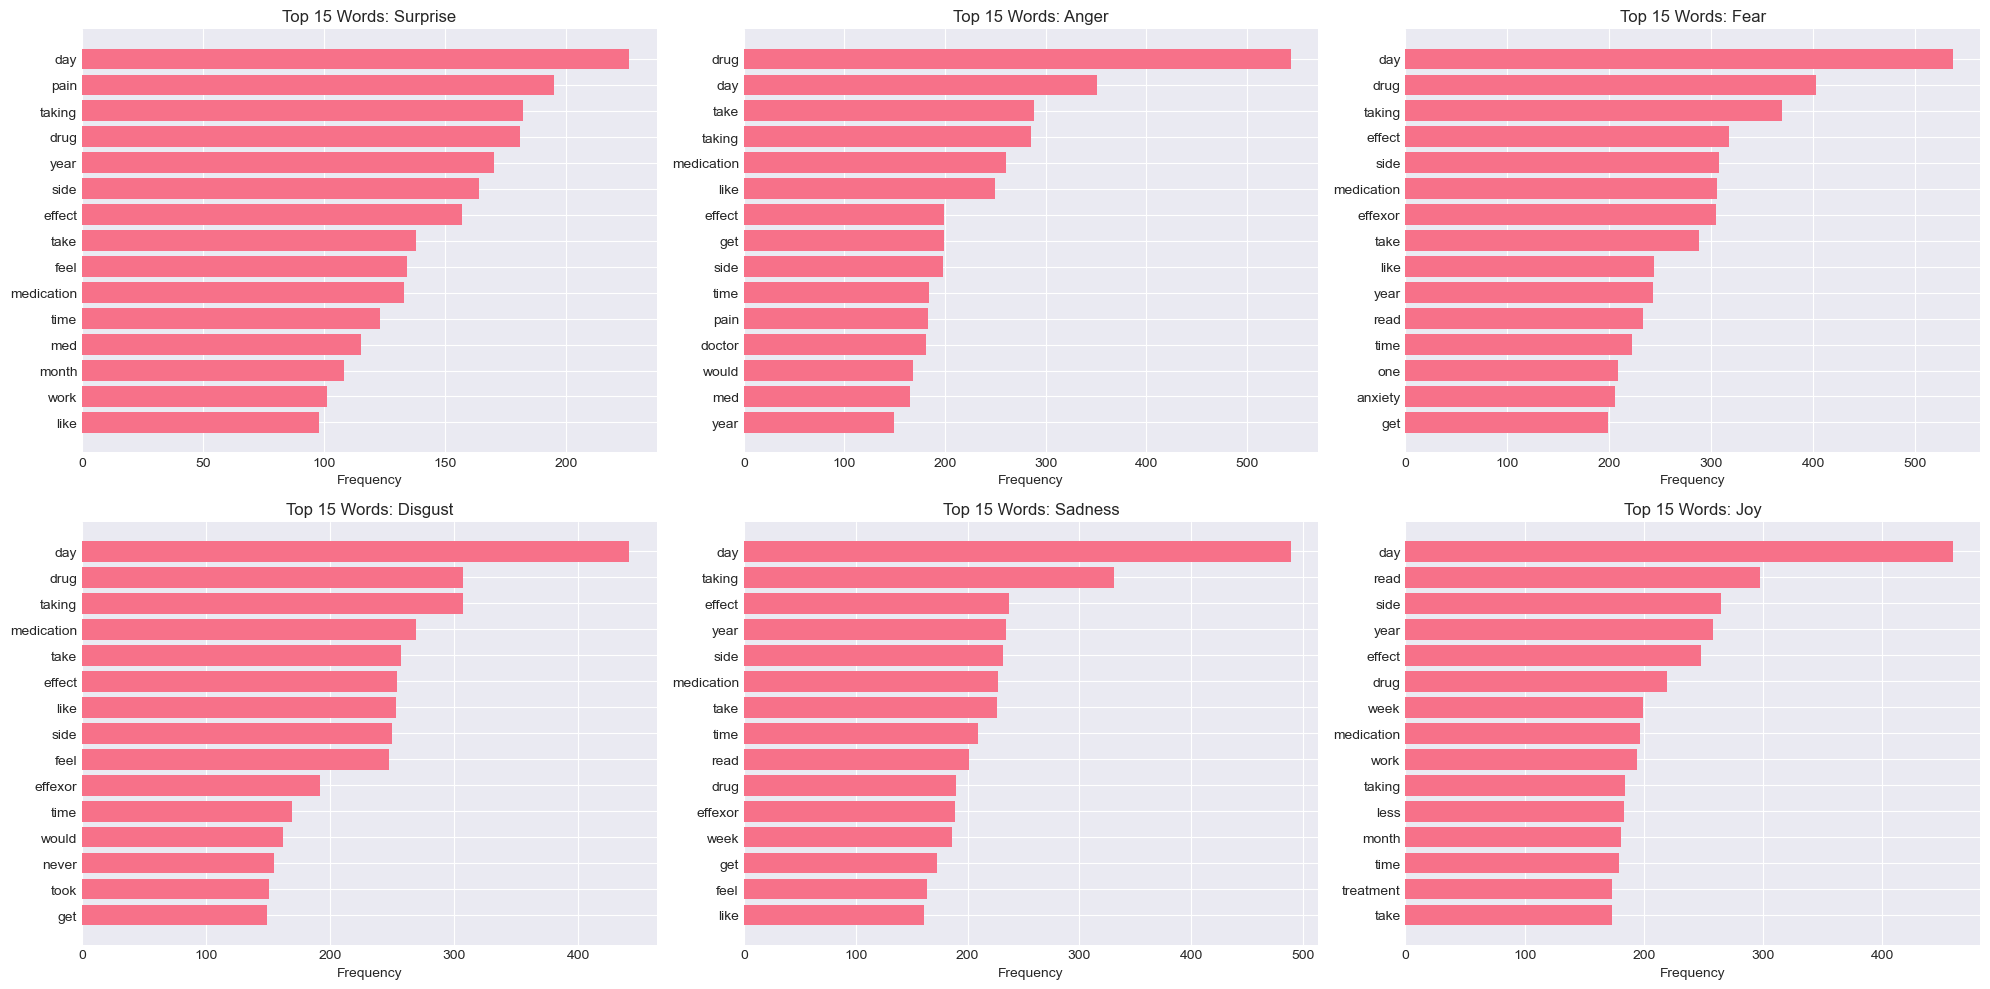


6. ADDITIONAL STATISTICS:
   Average words per review: 32.1
   Median words per review: 24.0
   Standard deviation of word count: 28.2
   Shortest review: 1 words
   Longest review: 185 words

7. CLASS IMBALANCE ANALYSIS:
   Maximum class imbalance ratio: 1.31:1
   Minority class: surprise (651 samples)
   Majority class: joy (850 samples)
   ✓ Classes are relatively balanced

8. SAMPLE REVIEWS BY EMOTION:

   ANGER:
     - husband taking med made mean angry went something else short tempered plain mean dont recommend prod...
     - husband horrible drug ended committing suicide acted strange drug doctor never anything drug dangero...

   DISGUST:
     - help anxiety beconing freqent
     - effexor withdrawl horrible doctor inform pt side effect bad

   FEAR:
     - doctor prescribed anxiety attack office routine exam used major anxiety driving would major frustrat...
     - year old woman drug year although helped depression many people stated review cannot miss one day ca...

   JOY

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple
import warnings
warnings.filterwarnings('ignore')

# Set style for visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# NLTK Setup
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-eng')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Stopwords & Lemmatizer
STOPWORDS = set(stopwords.words("english"))
LEMM = WordNetLemmatizer()

# Allowed emotions
ALLOWED = {"fear", "anger", "joy", "surprise", "disgust", "sadness"}

# pick column functions
def pick_col(df: pd.DataFrame, candidates) -> str:
    """Return the first matching column name (case-insensitive)."""
    lowmap = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lowmap:
            return lowmap[cand.lower()]
    raise KeyError(f"None of these columns were found: {candidates}")

# load dataset
def load_dataset(path: str) -> pd.DataFrame:
    """Load dataset with automatic format detection."""
    if path.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path)
    elif path.lower().endswith(".csv"):
        df = pd.read_csv(path)
    else:
        raise ValueError("Unsupported file format. Use .xlsx, .xls, or .csv")
    return df

# Normalise labels
SYN_MAP = {
    "sad": "sadness", "sadness": "sadness",
    "angry": "anger", "anger": "anger",
    "joyful": "joy", "happiness": "joy", "happy": "joy", "joy": "joy",
    "surprised": "surprise", "astonished": "surprise", "shock": "surprise", "surprise": "surprise",
    "fearful": "fear", "scared": "fear", "anxious": "fear", "fear": "fear",
    "disgusted": "disgust", "revulsion": "disgust", "disgust": "disgust",
}

def normalize_label(x: str) -> str | None:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return None
    s = str(x).strip().lower()
    s = re.sub(r"[^a-z]", "", s)  # keep letters only
    mapped = SYN_MAP.get(s, s)
    return mapped if mapped in ALLOWED else None

# clean text functions
def clean_text(text: str) -> str:
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ""
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)          # remove URLs
    t = re.sub(r"[@#]\w+", " ", t)                   # remove mentions/hashtags
    t = re.sub(r"[^a-z\s]", " ", t)                  # keep only letters
    tokens = [w for w in t.split() if w not in STOPWORDS and len(w) > 2]
    lemmas = [LEMM.lemmatize(w) for w in tokens]
    return " ".join(lemmas)

# Enhanced data insights functions
def analyze_text_lengths(df, text_col, emotion_col):
    """Analyze text length distribution by emotion."""
    df['text_length'] = df[text_col].astype(str).apply(len)
    df['word_count'] = df[text_col].astype(str).apply(lambda x: len(str(x).split()))

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Text length distribution
    axes[0, 0].hist(df['text_length'], bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    axes[0, 0].set_title('Distribution of Text Length (Characters)')
    axes[0, 0].set_xlabel('Text Length')
    axes[0, 0].set_ylabel('Frequency')

    # Word count distribution
    axes[0, 1].hist(df['word_count'], bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
    axes[0, 1].set_title('Distribution of Word Count')
    axes[0, 1].set_xlabel('Word Count')
    axes[0, 1].set_ylabel('Frequency')

    # Text length by emotion
    emotion_lengths = df.groupby(emotion_col)['text_length'].mean().sort_values(ascending=False)
    axes[1, 0].bar(range(len(emotion_lengths)), emotion_lengths.values, color='lightgreen')
    axes[1, 0].set_title('Average Text Length by Emotion')
    axes[1, 0].set_xlabel('Emotion')
    axes[1, 0].set_ylabel('Average Length (Characters)')
    axes[1, 0].set_xticks(range(len(emotion_lengths)))
    axes[1, 0].set_xticklabels(emotion_lengths.index, rotation=45)

    # Word count by emotion
    emotion_words = df.groupby(emotion_col)['word_count'].mean().sort_values(ascending=False)
    axes[1, 1].bar(range(len(emotion_words)), emotion_words.values, color='gold')
    axes[1, 1].set_title('Average Word Count by Emotion')
    axes[1, 1].set_xlabel('Emotion')
    axes[1, 1].set_ylabel('Average Word Count')
    axes[1, 1].set_xticks(range(len(emotion_words)))
    axes[1, 1].set_xticklabels(emotion_words.index, rotation=45)

    plt.tight_layout()
    plt.show()

    return df

def analyze_emotion_distribution(df, emotion_col):
    """Analyze emotion distribution with visualizations."""
    emotion_counts = df[emotion_col].value_counts()
    emotion_percentages = df[emotion_col].value_counts(normalize=True) * 100

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Bar chart
    axes[0, 0].bar(range(len(emotion_counts)), emotion_counts.values, color=sns.color_palette("husl", len(emotion_counts)))
    axes[0, 0].set_title('Emotion Distribution (Count)')
    axes[0, 0].set_xlabel('Emotion')
    axes[0, 0].set_ylabel('Count')
    axes[0, 0].set_xticks(range(len(emotion_counts)))
    axes[0, 0].set_xticklabels(emotion_counts.index, rotation=45)

    # Add count labels on bars
    for i, v in enumerate(emotion_counts.values):
        axes[0, 0].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')

    # Pie chart
    wedges, texts, autotexts = axes[0, 1].pie(emotion_counts.values, labels=emotion_counts.index,
                                              autopct='%1.1f%%', startangle=90,
                                              colors=sns.color_palette("husl", len(emotion_counts)))
    axes[0, 1].set_title('Emotion Distribution (Percentage)')

    # Make percentage text bold
    for autotext in autotexts:
        autotext.set_fontweight('bold')

    # Horizontal bar chart
    y_pos = range(len(emotion_counts))
    axes[1, 0].barh(y_pos, emotion_counts.values, color=sns.color_palette("husl", len(emotion_counts)))
    axes[1, 0].set_yticks(y_pos)
    axes[1, 0].set_yticklabels(emotion_counts.index)
    axes[1, 0].set_title('Emotion Distribution (Horizontal)')
    axes[1, 0].set_xlabel('Count')

    # Donut chart
    axes[1, 1].pie(emotion_counts.values, labels=emotion_counts.index,
                   autopct='%1.1f%%', startangle=90,
                   colors=sns.color_palette("husl", len(emotion_counts)),
                   wedgeprops=dict(width=0.3))
    axes[1, 1].set_title('Emotion Distribution (Donut)')

    plt.tight_layout()
    plt.show()

    # Print statistics
    print("="*60)
    print("EMOTION DISTRIBUTION STATISTICS")
    print("="*60)
    print(f"Total samples: {len(df)}")
    print(f"Number of unique emotions: {len(emotion_counts)}")
    print("\nCount by emotion:")
    for emotion, count in emotion_counts.items():
        percentage = emotion_percentages[emotion]
        print(f"  {emotion:15s}: {count:4d} ({percentage:5.1f}%)")

    print(f"\nMost common emotion: {emotion_counts.index[0]} ({emotion_counts.iloc[0]} samples)")
    print(f"Least common emotion: {emotion_counts.index[-1]} ({emotion_counts.iloc[-1]} samples)")
    print(f"Imbalance ratio: {emotion_counts.iloc[0] / emotion_counts.iloc[-1]:.2f}:1")

    return emotion_counts, emotion_percentages

def analyze_text_cleanliness(df, original_col, cleaned_col):
    """Analyze text cleaning effectiveness."""
    df['original_length'] = df[original_col].astype(str).apply(len)
    df['cleaned_length'] = df[cleaned_col].apply(len)
    df['reduction_percentage'] = ((df['original_length'] - df['cleaned_length']) / df['original_length'] * 100).fillna(0)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Length comparison
    axes[0].scatter(df['original_length'], df['cleaned_length'], alpha=0.6, color='blue')
    axes[0].plot([0, df['original_length'].max()], [0, df['original_length'].max()], 'r--', alpha=0.5)
    axes[0].set_title('Original vs Cleaned Text Length')
    axes[0].set_xlabel('Original Length')
    axes[0].set_ylabel('Cleaned Length')
    axes[0].grid(True, alpha=0.3)

    # Reduction percentage distribution
    axes[1].hist(df['reduction_percentage'], bins=50, alpha=0.7, color='green', edgecolor='black')
    axes[1].set_title('Text Length Reduction Percentage')
    axes[1].set_xlabel('Reduction Percentage (%)')
    axes[1].set_ylabel('Frequency')

    # Box plot of reduction by emotion
    box_data = [df[df['emotion'] == emotion]['reduction_percentage'].values
                for emotion in df['emotion'].unique()]
    axes[2].boxplot(box_data, labels=df['emotion'].unique())
    axes[2].set_title('Text Reduction by Emotion')
    axes[2].set_xlabel('Emotion')
    axes[2].set_ylabel('Reduction Percentage (%)')
    axes[2].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    # Print cleaning statistics
    print("\n" + "="*60)
    print("TEXT CLEANING STATISTICS")
    print("="*60)
    print(f"Average original text length: {df['original_length'].mean():.1f} characters")
    print(f"Average cleaned text length: {df['cleaned_length'].mean():.1f} characters")
    print(f"Average reduction: {df['reduction_percentage'].mean():.1f}%")
    print(f"Maximum reduction: {df['reduction_percentage'].max():.1f}%")
    print(f"Minimum reduction: {df['reduction_percentage'].min():.1f}%")

    return df

def analyze_common_words_by_emotion(df, text_col, emotion_col, top_n=20):
    """Analyze most common words by emotion."""
    from collections import Counter

    emotion_words = {}
    for emotion in df[emotion_col].unique():
        all_text = ' '.join(df[df[emotion_col] == emotion][text_col])
        words = all_text.split()
        word_counts = Counter(words)
        emotion_words[emotion] = word_counts.most_common(top_n)

    # Create subplots
    num_emotions = len(emotion_words)
    fig, axes = plt.subplots(2, (num_emotions + 1) // 2, figsize=(20, 10))
    axes = axes.flatten()

    for idx, (emotion, word_list) in enumerate(emotion_words.items()):
        if idx < len(axes):
            words, counts = zip(*word_list)
            y_pos = range(len(words))
            axes[idx].barh(y_pos, counts, color=sns.color_palette("husl", 1))
            axes[idx].set_yticks(y_pos)
            axes[idx].set_yticklabels(words)
            axes[idx].invert_yaxis()
            axes[idx].set_title(f'Top {top_n} Words: {emotion.capitalize()}')
            axes[idx].set_xlabel('Frequency')

    # Hide unused subplots
    for idx in range(len(emotion_words), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

    return emotion_words

def prepare_df(df: pd.DataFrame) -> Tuple[pd.Series, pd.Series]:
    """Prepare the dataframe with text cleaning and label normalization."""
    # Detect text and label columns automatically
    text_col = pick_col(df, ["Review", "Tweets", "Text", "Sentence"])
    label_col = pick_col(df, ["Emotion", "Feeling", "Emotion", "Label", "Sentiment"])

    print("="*60)
    print("DATA PREPARATION SUMMARY")
    print("="*60)
    print(f"Text column detected: {text_col}")
    print(f"Label column detected: {label_col}")
    print(f"Original dataset shape: {df.shape}")
    print(f"Original columns: {list(df.columns)}")

    # Show sample of original data
    print("\nSample of original data (first 5 rows):")
    print(df[[text_col, label_col]].head())

    # Check for missing values
    print(f"\nMissing values in text column: {df[text_col].isnull().sum()}")
    print(f"Missing values in label column: {df[label_col].isnull().sum()}")

    # Normalize and filter labels
    y = df[label_col].apply(normalize_label)
    mask_valid = y.notnull() & df[text_col].notna() & (df[text_col].astype(str).str.strip() != "")
    df2 = df.loc[mask_valid, [text_col]].copy()
    y = y.loc[mask_valid]

    print(f"\nSamples after removing invalid data: {len(df2)}")
    print(f"Samples removed: {len(df) - len(df2)}")

    # Clean text
    X_clean = df2[text_col].apply(clean_text)

    # Drop rows with empty cleaned text
    keep = X_clean.str.len() > 0
    X_clean, y = X_clean[keep], y[keep]

    print(f"Samples after removing empty cleaned text: {len(X_clean)}")
    print(f"Additional samples removed: {len(df2) - len(X_clean)}")

    # Create final dataframe
    cleaned_df = pd.DataFrame({
        "original_text": df2.loc[keep, text_col],
        "clean_text": X_clean,
        "original_emotion": df.loc[mask_valid, label_col][keep],
        "emotion": y
    }).reset_index(drop=True)

    # Show label distribution
    print("\n" + "="*60)
    print("LABEL DISTRIBUTION AFTER CLEANING")
    print("="*60)
    label_dist = y.value_counts().reindex(sorted(ALLOWED)).fillna(0).astype(int)
    for emotion, count in label_dist.items():
        percentage = (count / len(y)) * 100
        print(f"{emotion:15s}: {count:4d} ({percentage:5.1f}%)")

    print(f"\nTotal cleaned samples: {len(cleaned_df)}")
    print("Unique labels after cleaning:", sorted(y.unique()))

    return X_clean, y, cleaned_df, text_col, label_col

# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("="*60)
print("MEDICAL REVIEW EMOTION ANALYSIS")
print("="*60)

# Load dataset from local file
try:
    df = load_dataset("Full Final Medicine Reviews 4500.xlsx")
    print(f"Dataset loaded successfully from 'Final Medicine Reviews 4500 '")
    print(f"File shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
except FileNotFoundError:
    print("Error: File 'Final Medicine Reviews 4500 ' not found in current directory.")
    print("Please ensure the file is in the same directory as this script.")
    print("Trying common extensions...")
    for ext in ['.xlsx', '.xls', '.csv']:
        try:
            df = load_dataset(f"Final Medicine Reviews 4500 {ext}")
            print(f"Found file: Final Medicine Reviews 4500 {ext}")
            break
        except:
            continue
    else:
        raise FileNotFoundError("Could not find Final Medicine Reviews 4500  file with common extensions (.xlsx, .xls, .csv)")

# Prepare the dataframe
X_clean, y, cleaned_df, text_col, label_col = prepare_df(df)

# Save cleaned data
cleaned_df.to_csv("cleaned_medical_reviews.csv", index=False)
print(f"\nCleaned data saved to 'cleaned_medical_reviews.csv'")

# ============================================================================
# ENHANCED DATA INSIGHTS
# ============================================================================

print("\n" + "="*60)
print("ENHANCED DATA INSIGHTS")
print("="*60)

# 1. Basic dataset overview
print("\n1. DATASET OVERVIEW:")
print(f"   Total samples: {len(cleaned_df)}")
print(f"   Features per sample: {len(cleaned_df.columns)}")
print(f"   Data types:")
for col in cleaned_df.columns:
    print(f"     - {col}: {cleaned_df[col].dtype}")

# 2. Emotion distribution analysis
print("\n2. EMOTION ANALYSIS:")
emotion_counts, emotion_percentages = analyze_emotion_distribution(cleaned_df, "emotion")

# 3. Text length analysis
print("\n3. TEXT LENGTH ANALYSIS:")
cleaned_df = analyze_text_lengths(cleaned_df, "clean_text", "emotion")

# 4. Text cleaning analysis
print("\n4. TEXT CLEANING ANALYSIS:")
cleaned_df = analyze_text_cleanliness(cleaned_df, "original_text", "clean_text")

# 5. Common words analysis
print("\n5. COMMON WORDS ANALYSIS:")
common_words = analyze_common_words_by_emotion(cleaned_df, "clean_text", "emotion", top_n=15)

# 6. Additional statistics
print("\n6. ADDITIONAL STATISTICS:")
print(f"   Average words per review: {cleaned_df['word_count'].mean():.1f}")
print(f"   Median words per review: {cleaned_df['word_count'].median():.1f}")
print(f"   Standard deviation of word count: {cleaned_df['word_count'].std():.1f}")
print(f"   Shortest review: {cleaned_df['word_count'].min()} words")
print(f"   Longest review: {cleaned_df['word_count'].max()} words")

# 7. Class imbalance analysis
print("\n7. CLASS IMBALANCE ANALYSIS:")
if len(emotion_counts) > 1:
    imbalance_ratio = emotion_counts.max() / emotion_counts.min()
    print(f"   Maximum class imbalance ratio: {imbalance_ratio:.2f}:1")
    print(f"   Minority class: {emotion_counts.idxmin()} ({emotion_counts.min()} samples)")
    print(f"   Majority class: {emotion_counts.idxmax()} ({emotion_counts.max()} samples)")

    if imbalance_ratio > 5:
        print("   ⚠️  Warning: Significant class imbalance detected!")
    elif imbalance_ratio > 2:
        print("   ⚠️  Note: Moderate class imbalance detected")
    else:
        print("   ✓ Classes are relatively balanced")

# 8. Sample preview
print("\n8. SAMPLE REVIEWS BY EMOTION:")
for emotion in sorted(cleaned_df['emotion'].unique()):
    samples = cleaned_df[cleaned_df['emotion'] == emotion].head(2)
    print(f"\n   {emotion.upper()}:")
    for idx, row in samples.iterrows():
        text_preview = row['clean_text'][:100] + "..." if len(row['clean_text']) > 100 else row['clean_text']
        print(f"     - {text_preview}")

# ============================================================================
# TF-IDF VECTORIZATION FOR MODELING
# ============================================================================

print("\n" + "="*60)
print("TF-IDF VECTORIZATION")
print("="*60)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# --- Full dataset TF-IDF ---
tfidf_full = TfidfVectorizer(
    max_features=5000,   # keep top 5000 words
    ngram_range=(1,2),   # unigrams + bigrams
    stop_words="english" # remove stopwords
)
X_vec = tfidf_full.fit_transform(X_clean)  # Full dataset vectorized

print(f"Full dataset vectorized shape: {X_vec.shape}")
print(f"Vocabulary size: {len(tfidf_full.vocabulary_)}")

# --- Train-Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {len(X_train)}")
print(f"Test size: {len(X_test)}")
print(f"Train/Test ratio: {len(X_train)/len(X_test):.2f}:1")

# --- TF-IDF Vectorization on train-test split ---
tfidf_split = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    stop_words="english"
)
X_train_vec = tfidf_split.fit_transform(X_train)
X_test_vec = tfidf_split.transform(X_test)

print(f"\nTrain TF-IDF shape: {X_train_vec.shape}")
print(f"Test TF-IDF shape: {X_test_vec.shape}")

# Analyze feature sparsity
train_sparsity = 1.0 - (X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1]))
print(f"\nTF-IDF Matrix Statistics:")
print(f"  Train matrix sparsity: {train_sparsity:.3%}")
print(f"  Number of non-zero elements: {X_train_vec.nnz}")
print(f"  Average non-zero per sample: {X_train_vec.nnz / X_train_vec.shape[0]:.1f}")

print("\n" + "="*60)
print("ANALYSIS COMPLETE - DATA READY FOR MODELING")
print("="*60)


IMPROVED MODELING WITH CLASS IMBALANCE HANDLING
Label mapping: {'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'sadness': 4, 'surprise': 5}

Improved TF-IDF shape: (4499, 4718)
Vocabulary size: 4718

Train size: 3599
Test size: 900
Train/Test ratio: 4.00:1

Class distribution in training set:
  anger          :  559 ( 15.5%)
  disgust        :  607 ( 16.9%)
  fear           :  593 ( 16.5%)
  joy            :  680 ( 18.9%)
  sadness        :  639 ( 17.8%)
  surprise       :  521 ( 14.5%)

TRAINING ENHANCED MODELS

🔹 Training Naive Bayes...
Accuracy: 0.5078
Macro F1: 0.5014
Weighted F1: 0.5032

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.54      0.49      0.51       140
     disgust       0.46      0.45      0.45       152
        fear       0.51      0.49      0.50       148
         joy       0.58      0.74      0.65       170
     sadness       0.40      0.38      0.39       160
    surprise       0.53      0.48      0.5

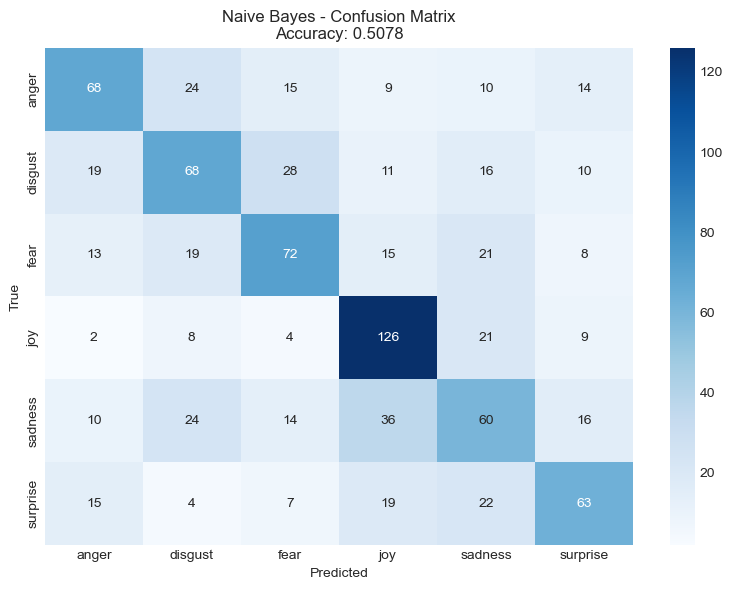


🔹 Training SVM...
Accuracy: 0.5267
Macro F1: 0.5214
Weighted F1: 0.5234

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.51      0.54      0.52       140
     disgust       0.44      0.44      0.44       152
        fear       0.53      0.51      0.52       148
         joy       0.63      0.72      0.68       170
     sadness       0.47      0.40      0.43       160
    surprise       0.54      0.53      0.53       130

    accuracy                           0.53       900
   macro avg       0.52      0.52      0.52       900
weighted avg       0.52      0.53      0.52       900



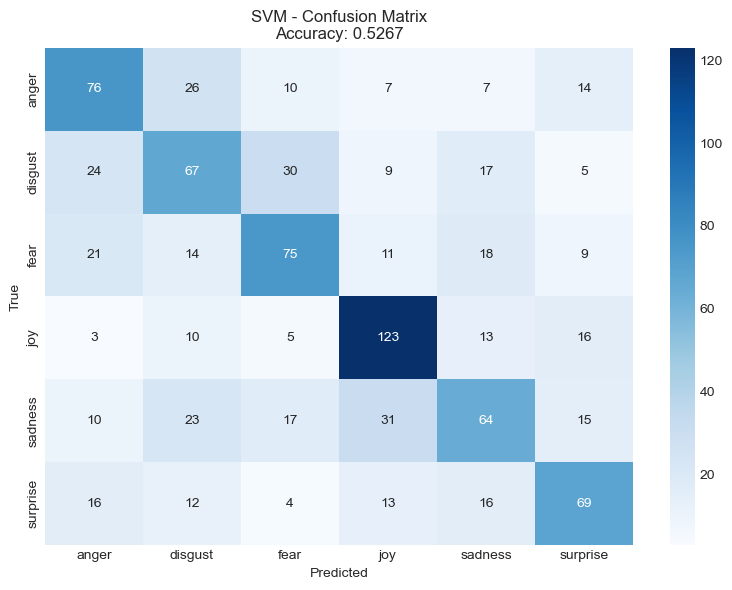


🔹 Training Decision Tree...
Accuracy: 0.3089
Macro F1: 0.3022
Weighted F1: 0.3015

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.39      0.27      0.32       140
     disgust       0.24      0.18      0.21       152
        fear       0.36      0.20      0.26       148
         joy       0.47      0.24      0.32       170
     sadness       0.24      0.66      0.35       160
    surprise       0.55      0.27      0.36       130

    accuracy                           0.31       900
   macro avg       0.37      0.31      0.30       900
weighted avg       0.37      0.31      0.30       900



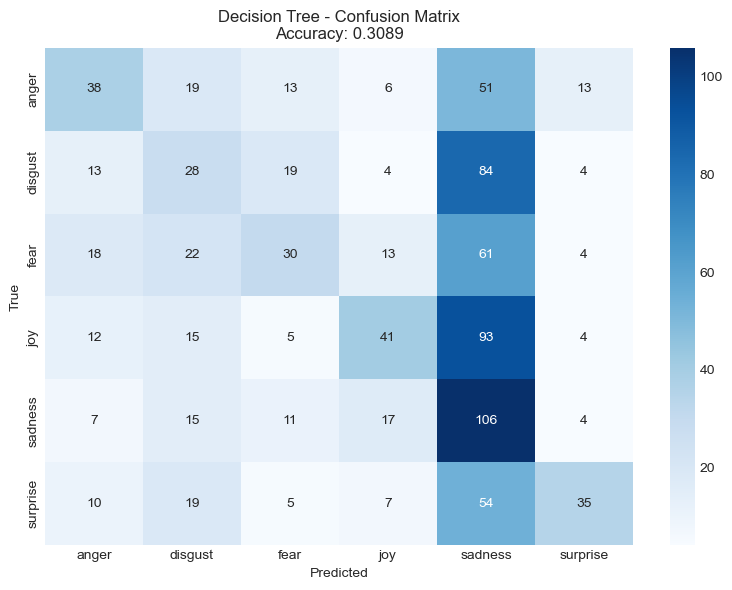


🔹 Training Logistic Regression...
Accuracy: 0.5400
Macro F1: 0.5346
Weighted F1: 0.5357

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.53      0.56      0.55       140
     disgust       0.48      0.50      0.49       152
        fear       0.55      0.52      0.53       148
         joy       0.64      0.74      0.68       170
     sadness       0.44      0.36      0.40       160
    surprise       0.57      0.55      0.56       130

    accuracy                           0.54       900
   macro avg       0.53      0.54      0.53       900
weighted avg       0.53      0.54      0.54       900



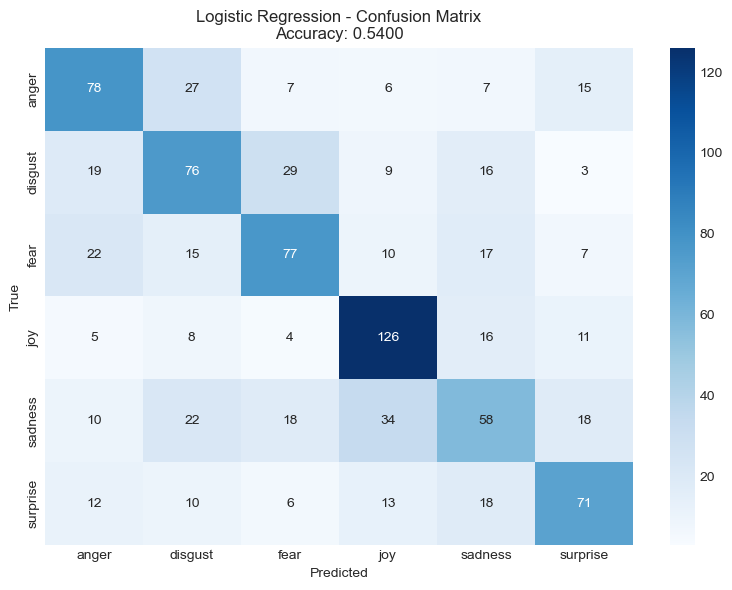


🔹 Training Random Forest...
Accuracy: 0.4889
Macro F1: 0.4761
Weighted F1: 0.4754

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.53      0.50      0.51       140
     disgust       0.43      0.45      0.44       152
        fear       0.49      0.51      0.50       148
         joy       0.51      0.72      0.60       170
     sadness       0.44      0.21      0.29       160
    surprise       0.50      0.52      0.51       130

    accuracy                           0.49       900
   macro avg       0.48      0.49      0.48       900
weighted avg       0.48      0.49      0.48       900



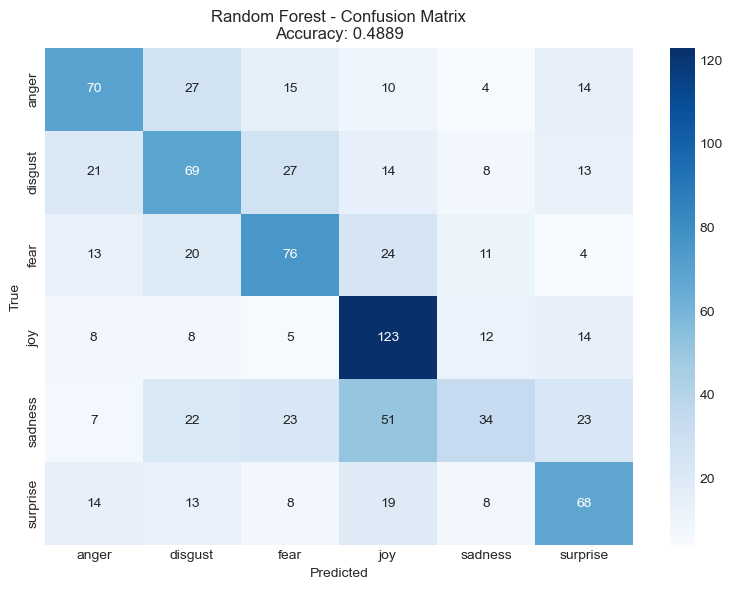


🔹 Training Gradient Boosting...
Accuracy: 0.4567
Macro F1: 0.4560
Weighted F1: 0.4579

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.42      0.36      0.39       140
     disgust       0.40      0.42      0.41       152
        fear       0.49      0.44      0.46       148
         joy       0.58      0.62      0.60       170
     sadness       0.33      0.42      0.37       160
    surprise       0.58      0.44      0.50       130

    accuracy                           0.46       900
   macro avg       0.47      0.45      0.46       900
weighted avg       0.47      0.46      0.46       900



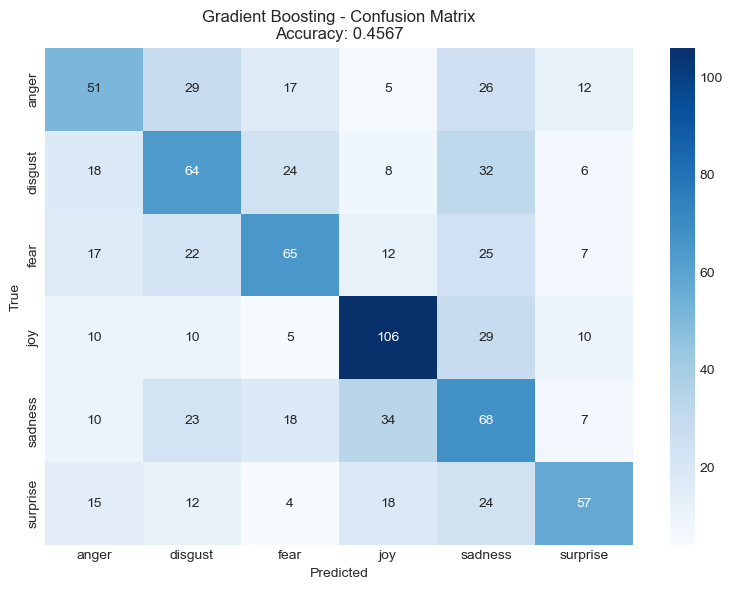


🔹 Training KNN...
Accuracy: 0.1900
Macro F1: 0.0886
Weighted F1: 0.0908

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.36      0.03      0.05       140
     disgust       0.42      0.03      0.06       152
        fear       0.00      0.00      0.00       148
         joy       0.57      0.02      0.05       170
     sadness       0.18      0.96      0.30       160
    surprise       0.83      0.04      0.07       130

    accuracy                           0.19       900
   macro avg       0.39      0.18      0.09       900
weighted avg       0.39      0.19      0.09       900



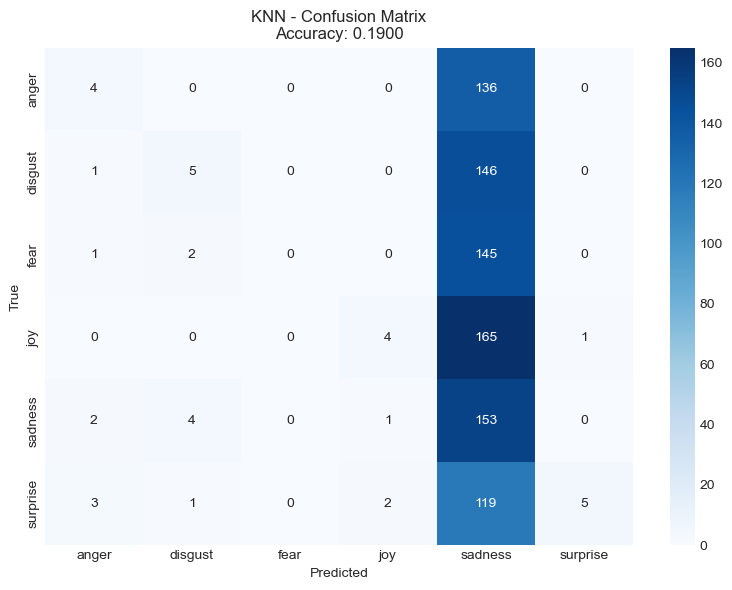


🔹 Training SVM + SMOTE...
Accuracy: 0.5267
Macro F1: 0.5216
Weighted F1: 0.5238

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.49      0.53      0.51       140
     disgust       0.44      0.45      0.45       152
        fear       0.53      0.53      0.53       148
         joy       0.64      0.72      0.68       170
     sadness       0.47      0.40      0.43       160
    surprise       0.56      0.52      0.54       130

    accuracy                           0.53       900
   macro avg       0.52      0.52      0.52       900
weighted avg       0.52      0.53      0.52       900



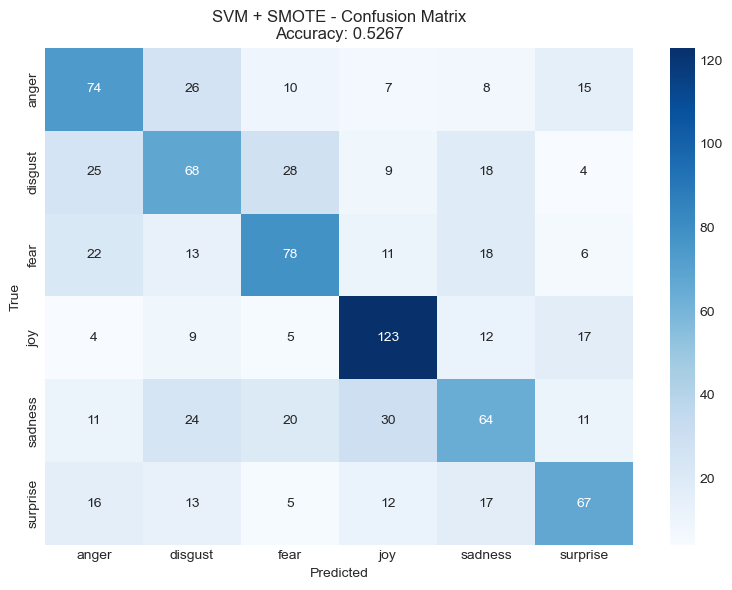


🔹 Training Logistic + SMOTE...
Accuracy: 0.5378
Macro F1: 0.5322
Weighted F1: 0.5334

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.52      0.54      0.53       140
     disgust       0.47      0.48      0.48       152
        fear       0.55      0.55      0.55       148
         joy       0.63      0.74      0.68       170
     sadness       0.44      0.36      0.40       160
    surprise       0.57      0.54      0.55       130

    accuracy                           0.54       900
   macro avg       0.53      0.54      0.53       900
weighted avg       0.53      0.54      0.53       900



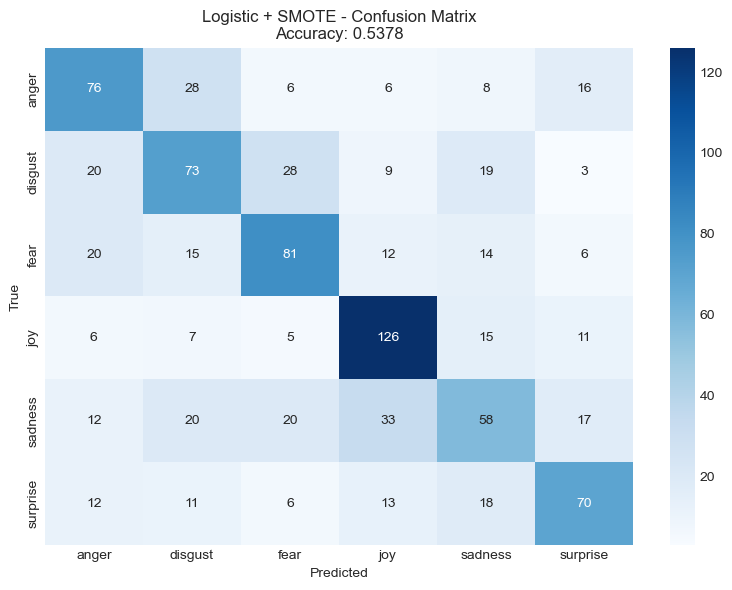


🔹 Training Random Forest + SMOTE...
Accuracy: 0.4900
Macro F1: 0.4772
Weighted F1: 0.4778

Detailed Classification Report:
              precision    recall  f1-score   support

       anger       0.52      0.48      0.50       140
     disgust       0.42      0.41      0.42       152
        fear       0.48      0.49      0.48       148
         joy       0.53      0.77      0.63       170
     sadness       0.43      0.26      0.32       160
    surprise       0.50      0.52      0.51       130

    accuracy                           0.49       900
   macro avg       0.48      0.49      0.48       900
weighted avg       0.48      0.49      0.48       900



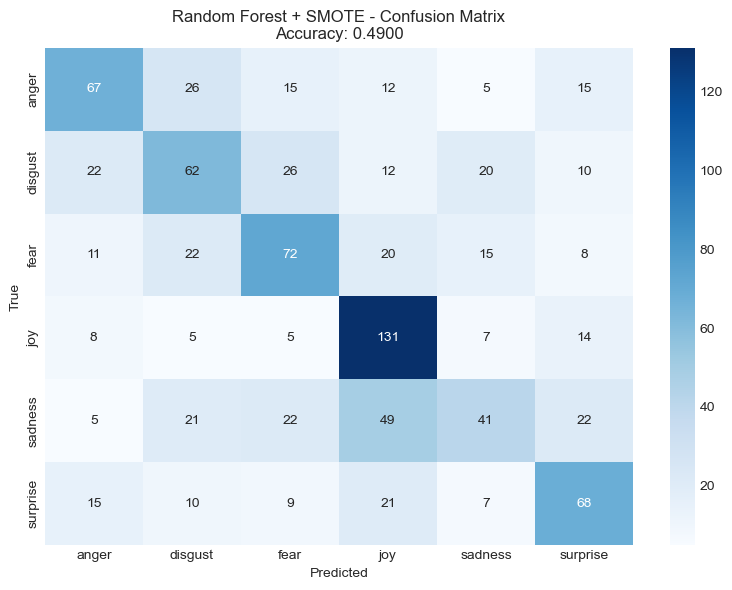


MODEL PERFORMANCE COMPARISON

📊 Model Performance Ranking:
                Model  Accuracy
  Logistic Regression  0.540000
     Logistic + SMOTE  0.537778
                  SVM  0.526667
          SVM + SMOTE  0.526667
          Naive Bayes  0.507778
Random Forest + SMOTE  0.490000
        Random Forest  0.488889
    Gradient Boosting  0.456667
        Decision Tree  0.308889
                  KNN  0.190000


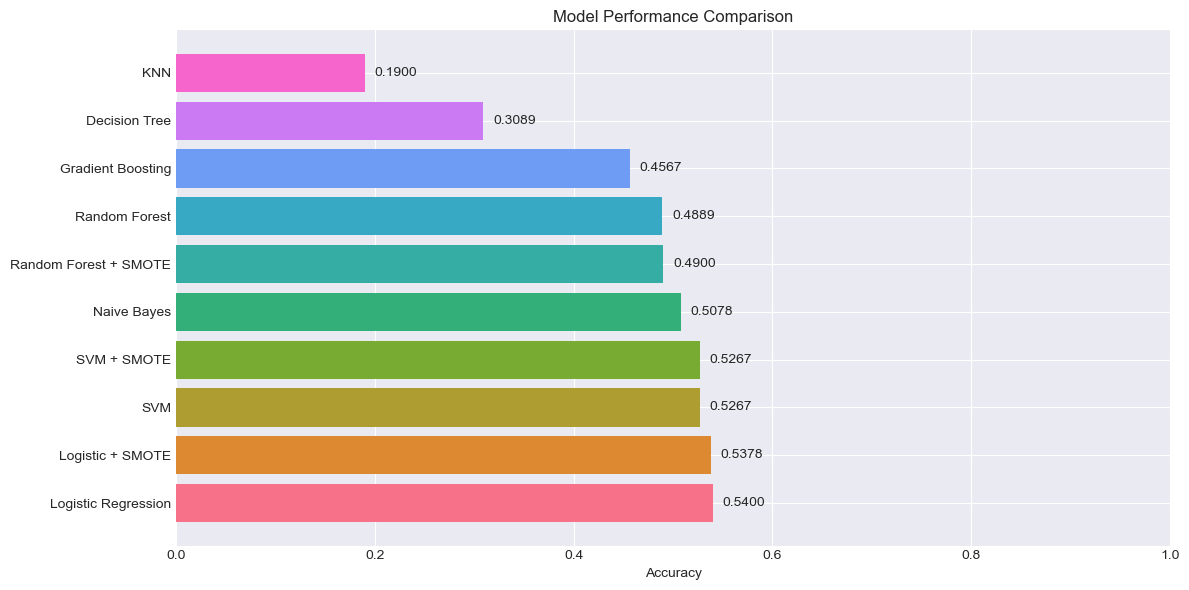


FEATURE IMPORTANCE ANALYSIS


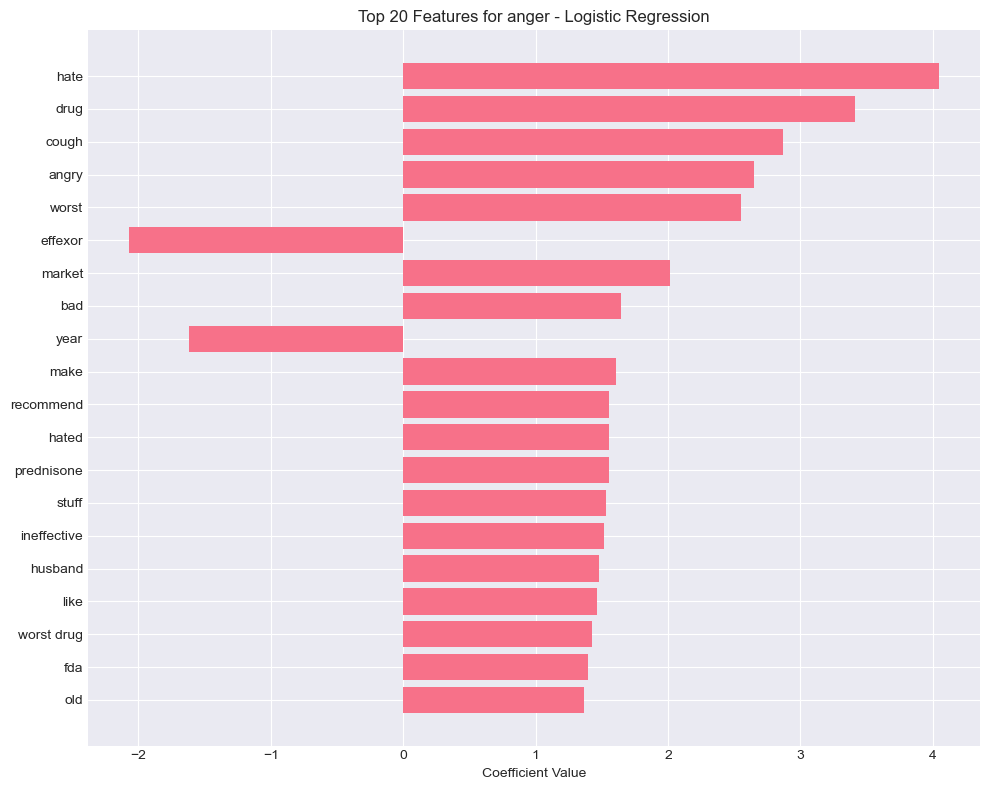

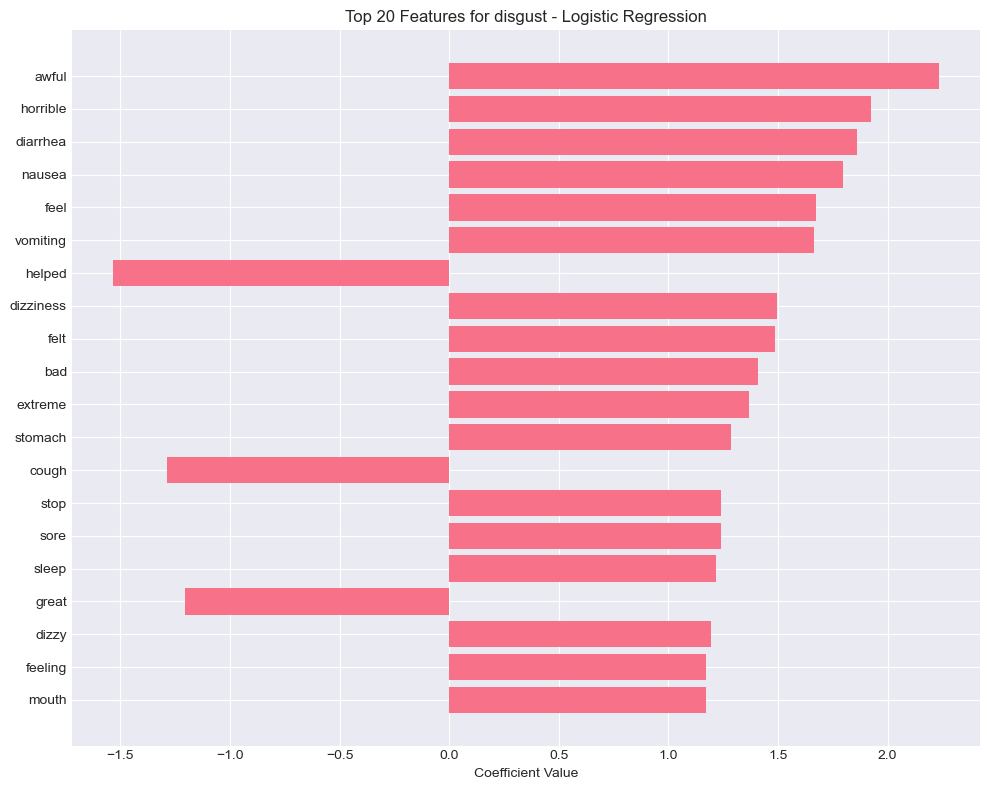

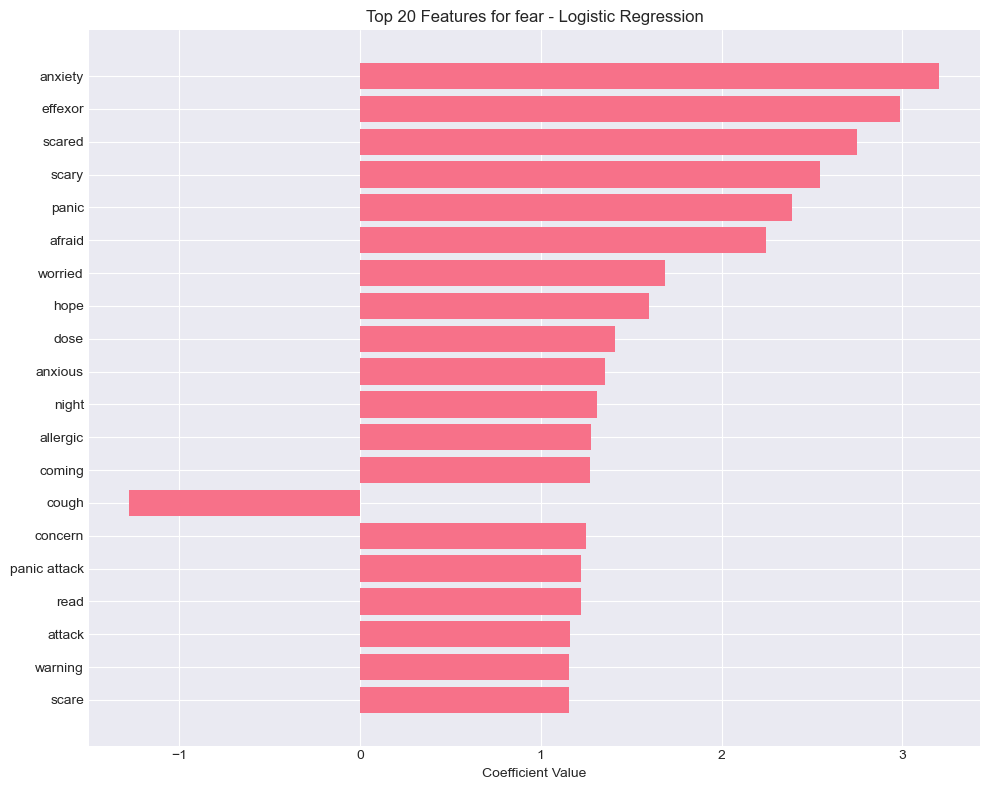

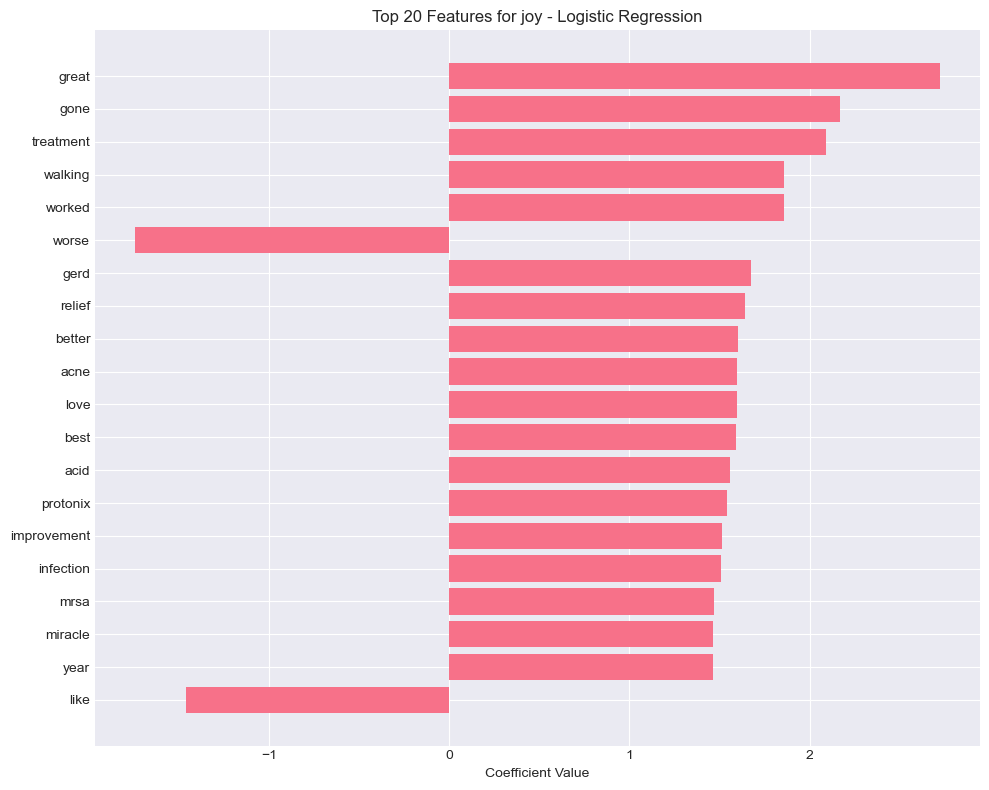

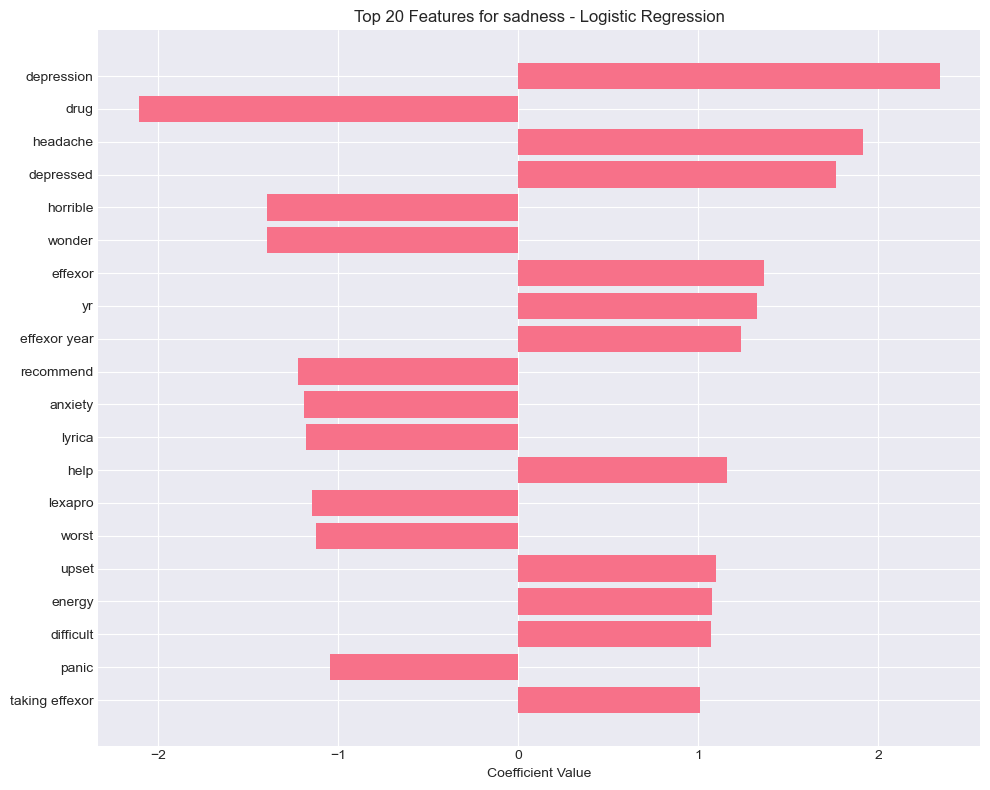

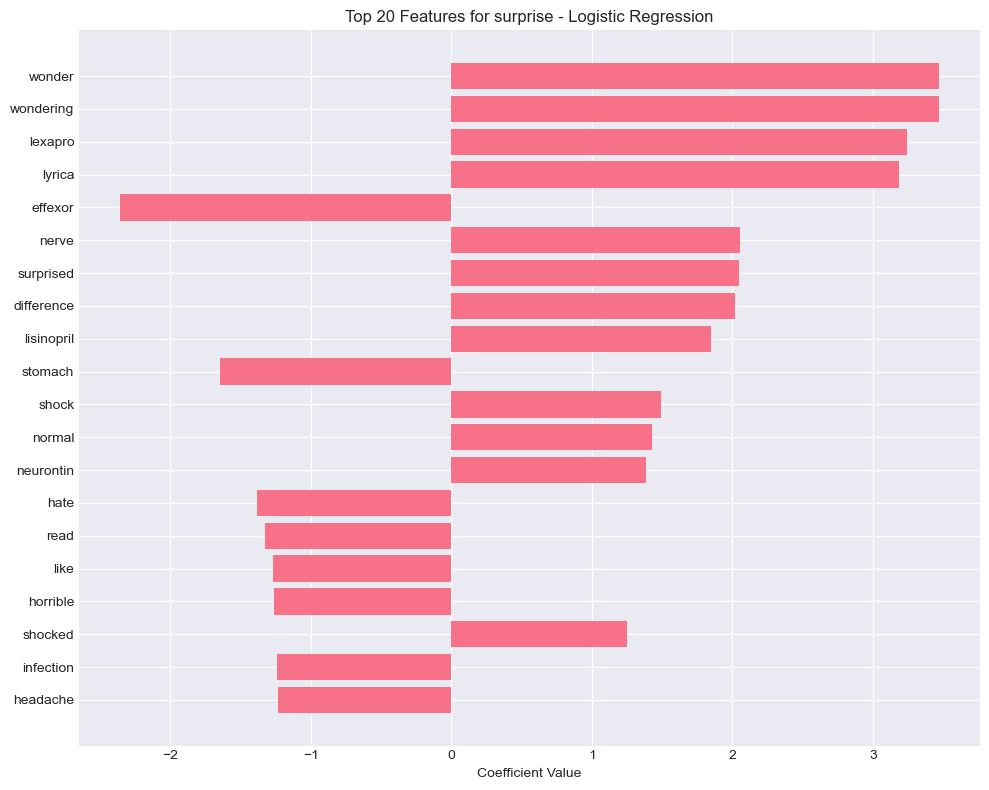


ERROR ANALYSIS

Misclassified samples: 414/900 (46.0%)

Misclassification Analysis:
sadness → joy: 34 samples
disgust → fear: 29 samples
anger → disgust: 27 samples
fear → anger: 22 samples
sadness → disgust: 22 samples
disgust → anger: 19 samples
sadness → surprise: 18 samples
sadness → fear: 18 samples
surprise → sadness: 18 samples
fear → sadness: 17 samples

Sample Misclassified Texts:

1. True: anger, Predicted: disgust
   Text: lisinopril completely lower caused extreme sun sensitivity get change med due blistering burning rash created...

2. True: fear, Predicted: anger
   Text: foot surgery developed little bit infection incision taken drug remember side effect time caused extremely sensitive sun light even minute outside leg...

3. True: surprise, Predicted: disgust
   Text: posting mainly say someone extremely sensitive drug side effect found easy adjust bothersome overall felt little buzzed digestive issue took drug tota...

4. True: surprise, Predicted: sadness
   Text: st

In [ ]:
# ============================================================================
# IMPROVED MODELING WITH CLASS IMBALANCE HANDLING
# ============================================================================

print("\n" + "="*60)
print("IMPROVED MODELING WITH CLASS IMBALANCE HANDLING")
print("="*60)

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings
warnings.filterwarnings('ignore')

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"Label mapping: {dict(zip(le.classes_, range(len(le.classes_))))}")

# --- Improved TF-IDF with better parameters ---
tfidf_improved = TfidfVectorizer(
    max_features=8000,           # Increased features
    min_df=5,                    # Ignore terms with document frequency < 5
    max_df=0.9,                  # Ignore terms with document frequency > 90%
    ngram_range=(1, 3),          # Unigrams, bigrams, trigrams
    stop_words="english",
    sublinear_tf=True,           # Apply sublinear TF scaling
    norm='l2',                   # Normalize vectors
    use_idf=True,
    smooth_idf=True
)

# Fit TF-IDF
X_vec_improved = tfidf_improved.fit_transform(X_clean)
print(f"\nImproved TF-IDF shape: {X_vec_improved.shape}")
print(f"Vocabulary size: {len(tfidf_improved.vocabulary_)}")

# --- Train-Test Split with stratification ---
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Apply TF-IDF separately
X_train_vec = tfidf_improved.fit_transform(X_train)
X_test_vec = tfidf_improved.transform(X_test)

print(f"\nTrain size: {len(X_train)}")
print(f"Test size: {len(X_test)}")
print(f"Train/Test ratio: {len(X_train)/len(X_test):.2f}:1")

# --- Analyze class distribution ---
print("\nClass distribution in training set:")
train_counts = pd.Series(y_train).value_counts().sort_index()
for idx, count in train_counts.items():
    emotion = le.inverse_transform([idx])[0]
    percentage = (count / len(y_train)) * 100
    print(f"  {emotion:15s}: {count:4d} ({percentage:5.1f}%)")

# ============================================================================
# ENHANCED MODELS WITH CLASS IMBALANCE HANDLING
# ============================================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# --- Define enhanced models with class weights ---
models_enhanced = {
    "Naive Bayes": MultinomialNB(alpha=0.1),  # Add smoothing
    "SVM": LinearSVC(class_weight='balanced', max_iter=5000, C=0.5, random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=20),
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000,
                                             random_state=42, C=1.0),
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=200,
                                          random_state=42, max_depth=20),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42,
                                                   learning_rate=0.1, max_depth=5),
    "KNN": KNeighborsClassifier(n_neighbors=10, weights='distance')  # Distance weighting
}

# Add SMOTE for specific models
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Models with SMOTE
smote_models = {
    "SVM + SMOTE": ImbPipeline([
        ('smote', SMOTE(random_state=42, sampling_strategy='auto')),
        ('svm', LinearSVC(class_weight='balanced', max_iter=5000, C=0.5, random_state=42))
    ]),
    "Logistic + SMOTE": ImbPipeline([
        ('smote', SMOTE(random_state=42, sampling_strategy='auto')),
        ('lr', LogisticRegression(class_weight='balanced', max_iter=1000,
                                 random_state=42, C=1.0))
    ]),
    "Random Forest + SMOTE": ImbPipeline([
        ('smote', SMOTE(random_state=42, sampling_strategy='auto')),
        ('rf', RandomForestClassifier(class_weight='balanced', n_estimators=200,
                                     random_state=42, max_depth=20))
    ])
}

# Combine all models
all_models = {**models_enhanced, **smote_models}

results_enhanced = {}
accuracy_scores = []
model_names = []

print("\n" + "="*60)
print("TRAINING ENHANCED MODELS")
print("="*60)

# Train and evaluate all models
for name, model in all_models.items():
    print(f"\n🔹 Training {name}...")

    try:
        # Fit model
        model.fit(X_train_vec, y_train)

        # Predict
        y_pred = model.predict(X_test_vec)

        # Calculate metrics
        acc = accuracy_score(y_test, y_pred)
        f1_macro = f1_score(y_test, y_pred, average='macro')
        f1_weighted = f1_score(y_test, y_pred, average='weighted')

        # Print results
        print(f"Accuracy: {acc:.4f}")
        print(f"Macro F1: {f1_macro:.4f}")
        print(f"Weighted F1: {f1_weighted:.4f}")

        # Save results
        results_enhanced[name] = {
            "model": model,
            "accuracy": acc,
            "f1_macro": f1_macro,
            "f1_weighted": f1_weighted,
            "y_pred": y_pred
        }

        accuracy_scores.append(acc)
        model_names.append(name)

        # Detailed classification report
        print("\nDetailed Classification Report:")
        y_test_labels = le.inverse_transform(y_test)
        y_pred_labels = le.inverse_transform(y_pred)
        print(classification_report(y_test_labels, y_pred_labels, zero_division=0))

        # Confusion Matrix
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_test_labels, y_pred_labels, labels=le.classes_)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f"{name} - Confusion Matrix\nAccuracy: {acc:.4f}")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error training {name}: {str(e)}")
        continue

# ============================================================================
# MODEL COMPARISON AND VISUALIZATION
# ============================================================================

print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)

# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': model_names,
    'Accuracy': accuracy_scores
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("\n📊 Model Performance Ranking:")
print(comparison_df.to_string(index=False))

# Plot model comparison
plt.figure(figsize=(12, 6))
bars = plt.barh(range(len(comparison_df)), comparison_df['Accuracy'].values,
                color=sns.color_palette("husl", len(comparison_df)))
plt.yticks(range(len(comparison_df)), comparison_df['Model'].values)
plt.xlabel('Accuracy')
plt.title('Model Performance Comparison')
plt.xlim([0, 1])

# Add accuracy values on bars
for i, (bar, acc) in enumerate(zip(bars, comparison_df['Accuracy'].values)):
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2,
             f'{acc:.4f}', va='center')

plt.tight_layout()
plt.show()

# ============================================================================
# FEATURE IMPORTANCE ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*60)

# Get best model
best_model_name = comparison_df.iloc[0]['Model']
best_model = results_enhanced[best_model_name]['model']

# Extract feature names
feature_names = tfidf_improved.get_feature_names_out()

# Check if model has feature_importances_ or coef_ attribute
if hasattr(best_model, 'feature_importances_'):
    # For tree-based models
    importances = best_model.feature_importances_
    indices = np.argsort(importances)[-20:]  # Top 20 features

    plt.figure(figsize=(10, 8))
    plt.barh(range(20), importances[indices])
    plt.yticks(range(20), [feature_names[i] for i in indices])
    plt.xlabel('Feature Importance')
    plt.title(f'Top 20 Features - {best_model_name}')
    plt.tight_layout()
    plt.show()

elif hasattr(best_model, 'coef_'):
    # For linear models
    if len(best_model.coef_.shape) > 1:
        # Multi-class model
        for class_idx, class_name in enumerate(le.classes_):
            coef = best_model.coef_[class_idx]
            indices = np.argsort(np.abs(coef))[-20:]  # Top 20 features for this class

            plt.figure(figsize=(10, 8))
            plt.barh(range(20), coef[indices])
            plt.yticks(range(20), [feature_names[i] for i in indices])
            plt.xlabel('Coefficient Value')
            plt.title(f'Top 20 Features for {class_name} - {best_model_name}')
            plt.tight_layout()
            plt.show()
    else:
        # Binary classification
        coef = best_model.coef_[0]
        indices = np.argsort(np.abs(coef))[-20:]

        plt.figure(figsize=(10, 8))
        plt.barh(range(20), coef[indices])
        plt.yticks(range(20), [feature_names[i] for i in indices])
        plt.xlabel('Coefficient Value')
        plt.title(f'Top 20 Features - {best_model_name}')
        plt.tight_layout()
        plt.show()

# ============================================================================
# ERROR ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("ERROR ANALYSIS")
print("="*60)

# Get predictions from best model
y_pred_best = results_enhanced[best_model_name]['y_pred']
y_test_labels = le.inverse_transform(y_test)
y_pred_labels = le.inverse_transform(y_pred_best)

# Create error analysis dataframe
error_df = pd.DataFrame({
    'Original_Text': X_test.reset_index(drop=True),
    'True_Label': y_test_labels,
    'Predicted_Label': y_pred_labels,
    'Correct': y_test_labels == y_pred_labels
})

# Find misclassified samples
misclassified = error_df[~error_df['Correct']]
print(f"\nMisclassified samples: {len(misclassified)}/{len(error_df)} ({len(misclassified)/len(error_df)*100:.1f}%)")

# Analyze misclassifications by class
print("\nMisclassification Analysis:")
misclass_counts = misclassified.groupby(['True_Label', 'Predicted_Label']).size().reset_index(name='Count')
misclass_counts = misclass_counts.sort_values('Count', ascending=False)

for idx, row in misclass_counts.head(10).iterrows():
    print(f"{row['True_Label']} → {row['Predicted_Label']}: {row['Count']} samples")

# Show some misclassified examples
print("\nSample Misclassified Texts:")
for i, (_, row) in enumerate(misclassified.head(5).iterrows()):
    print(f"\n{i+1}. True: {row['True_Label']}, Predicted: {row['Predicted_Label']}")
    print(f"   Text: {row['Original_Text'][:150]}...")

# ============================================================================
# MODEL OPTIMIZATION SUGGESTIONS
# ============================================================================

print("\n" + "="*60)
print("MODEL OPTIMIZATION SUGGESTIONS")
print("="*60)

# Analyze class-wise performance
from sklearn.metrics import precision_recall_fscore_support

y_pred_best = results_enhanced[best_model_name]['y_pred']
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred_best, average=None)

print("\nClass-wise Performance:")
for i, emotion in enumerate(le.classes_):
    print(f"{emotion:15s}: Precision={precision[i]:.3f}, Recall={recall[i]:.3f}, F1={f1[i]:.3f}, Support={support[i]}")

# Suggestions based on analysis
print("\n📝 Recommendations:")
print("1. Classes with low recall (anger, disgust, fear, surprise) need more samples")
print("2. Consider data augmentation for minority classes")
print("3. Try ensemble methods combining multiple models")
print("4. Experiment with different text representations (word embeddings)")
print("5. Use stratified k-fold cross validation for more robust evaluation")

# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("\n" + "="*60)
print("FINAL SUMMARY")
print("="*60)
print(f"Best Model: {best_model_name}")
print(f"Best Accuracy: {results_enhanced[best_model_name]['accuracy']:.4f}")
print(f"Best Macro F1: {results_enhanced[best_model_name]['f1_macro']:.4f}")
print(f"Total Models Evaluated: {len(results_enhanced)}")
print(f"Dataset Size: {len(cleaned_df)} samples")
print(f"Number of Classes: {len(le.classes_)}")
print("\nAnalysis complete! 🎯")

In [ ]:
# ============================================================================
# NAIVE BAYES + SMOTE
# ============================================================================

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create pipeline with SMOTE + Naive Bayes
nb_smote_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42, sampling_strategy='auto')),
    ('nb', MultinomialNB(alpha=0.1))
])

# Train the model
nb_smote_pipeline.fit(X_train_vec, y_train)

# Predict and evaluate
y_pred_nb_smote = nb_smote_pipeline.predict(X_test_vec)

# Calculate metrics
accuracy_nb_smote = accuracy_score(y_test, y_pred_nb_smote)
f1_macro_nb_smote = f1_score(y_test, y_pred_nb_smote, average='macro')
f1_weighted_nb_smote = f1_score(y_test, y_pred_nb_smote, average='weighted')

print(f"Naive Bayes + SMOTE Results:")
print(f"Accuracy: {accuracy_nb_smote:.4f}")
print(f"Macro F1: {f1_macro_nb_smote:.4f}")
print(f"Weighted F1: {f1_weighted_nb_smote:.4f}")

# Classification report
y_test_labels = le.inverse_transform(y_test)
y_pred_labels = le.inverse_transform(y_pred_nb_smote)
print("\nClassification Report:")
print(classification_report(y_test_labels, y_pred_labels))

Naive Bayes + SMOTE Results:
Accuracy: 0.5089
Macro F1: 0.5042
Weighted F1: 0.5053

Classification Report:
              precision    recall  f1-score   support

       anger       0.52      0.49      0.50       140
     disgust       0.45      0.44      0.44       152
        fear       0.51      0.51      0.51       148
         joy       0.62      0.71      0.66       170
     sadness       0.39      0.35      0.37       160
    surprise       0.52      0.55      0.53       130

    accuracy                           0.51       900
   macro avg       0.50      0.51      0.50       900
weighted avg       0.50      0.51      0.51       900

